In [1]:
import requests
import pandas as pd

# List to store the data for each paper.
data = []

# Main Labels, each with 5 sub-topics containing 70 papers per sub-topic.
topics = {
    "Science": ["physics", "biology", "chemistry", "astronomy", "genetics"],
    "Business": ["marketing", "finance", "entrepreneurship", "supply chain", "accounting"],
    "Social Science": ["sociology", "psychology", "political science", "anthropology", "education"]
}

# For loop to get research paper abstracts for each label containing 5 sub-topics
for label in topics:
    for subtopic in topics[label]:
        
        # Fetch directly from Europe PMC API
        url = f"https://www.ebi.ac.uk/europepmc/webservices/rest/search?query={subtopic}&resultType=core&pageSize=150&format=json"
        response = requests.get(url)
        papers = response.json()['resultList']['result']
        
        count = 0
        for paper in papers:
            # Check if the paper has an abstract in the response
            if 'abstractText' in paper:
                abstract = paper['abstractText']
                
                # Append to the data list with the label and subtopic
                data.append({
                    'subtopic': subtopic,
                    'abstract': abstract,
                    'label': label
                })
                count = count + 1
                
                # We need exactly 70 papers for each subtopic
                if count == 70:
                    break


# Convert the list into a Pandas DataFrame and save to CSV
df = pd.DataFrame(data)
df.to_csv("dataset.csv", index=False)

This Cell collects the data which is research paper abstracts from PMC API and saves it as a csv file in desktop.

In [2]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

# Downloading NLTK resources for stopwords and lemmatization.
nltk.download('stopwords')
nltk.download('wordnet')

# Initialize stop words list and the lemmatizer
stop_words = set(stopwords.words('english'))
academic_stops = {'study', 'paper', 'research', 'result', 'results', 'method', 'methods', 'analysis', 'also', 'using', 'used'}
stop_words = stop_words.union(academic_stops)

lemmatizer = WordNetLemmatizer()

# Loop through every research abstract in the data and clean them.
cleaned_abstracts = []

for text in df['abstract']:
    # Remove HTML tags like <p>, <b> 
    text = re.sub(r'<.*?>', ' ', str(text))
    
    # Remove noise and lowercase
    text = re.sub(r'[^a-zA-Z\s]', '', text.lower())
    
    # Tokenize, basically splitting the sentance into words so that we can do lemmatization.
    words = text.split()
    
    # Remove stop words and short 1-2 letter noise words, then Lemmatize
    clean_words = []
    for w in words:
        if w not in stop_words and len(w) > 2:
            root_word = lemmatizer.lemmatize(w)
            clean_words.append(root_word)
    
    cleaned_abstracts.append(" ".join(clean_words))

# Saving new column in our DataFrame
df['clean_abstract'] = cleaned_abstracts
df.to_csv("dataset.csv", index=False)
print("Updated dataset.csv saved successfully!")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Dell\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Dell\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


Updated dataset.csv saved successfully!


This cell cleans the abstracts(remove stop words, lemmatize, remove noise) and saves new column of cleaned abstracts for each paper.

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

# TF-IDF(extracting top 2500 1-word and 2-word features to classify the research abstracts)
tfidf = TfidfVectorizer(max_features=2500, ngram_range=(1, 2))

# Convert cleaned text into numerical feature matrix X, and labels into y
X = tfidf.fit_transform(df['clean_abstract'])
y = df['label']

print("TF-IDF Matrix Shape (Papers, Features):", X.shape)

# Split dataset into 80% Training and 20% Testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y
)

print("Training set size:", X_train.shape[0])
print("Testing set size:", X_test.shape[0])

TF-IDF Matrix Shape (Papers, Features): (1050, 2500)
Training set size: 840
Testing set size: 210


This cell makes features(2500) from each word present in the abstract so that input feature size for modal evaluation becomes 2500.
Further it splits the dataset into training and testing(80:20).

In [4]:
import time
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# Defining all modals with their hyperparameters.
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=30, random_state=42),
    "Naive Bayes": MultinomialNB(alpha=0.2),
    "KNN": KNeighborsClassifier(n_neighbors=10, metric='cosine'),
    "SVM": SVC(kernel='linear', random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=40, random_state=42)
}

results = []

for name in models:
    model = models[name]
    
    # Measuring training time
    start_time = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - start_time
    
    # Prediction of 20% test data
    y_pred = model.predict(X_test)
    
    # Calculating test evaluation metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted')
    rec = recall_score(y_test, y_pred, average='weighted')
    f1 = f1_score(y_test, y_pred, average='weighted')
    
    # Calculating 5-Fold Cross-Validation accuracy for each model.
    cv_scores = cross_val_score(model, X, y, cv=5, scoring='accuracy')
    
    results.append({
        "Model": name,
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1-Score": round(f1, 4),
        "CV Mean": round(cv_scores.mean(), 4),
        "CV Std": round(cv_scores.std(), 4),
        "Train Time (s)": round(train_time, 4)
    })

# Complete comparison table
results_df = pd.DataFrame(results)
display(results_df)

,Model,Accuracy,Precision,Recall,F1-Score,CV Mean,CV Std,Train Time (s)
0,Logistic Regression,0.8905,0.8940,0.8905,0.8874,0.6933,0.0644,0.0676
1,Decision Tree,0.6857,0.6948,0.6857,0.6868,0.4676,0.0520,0.1379
2,Naive Bayes,0.8714,0.8773,0.8714,0.8680,0.7210,0.0605,0.0040
3,KNN,0.8762,0.8752,0.8762,0.8751,0.6324,0.0620,0.0040
4,SVM,0.8905,0.8936,0.8905,0.8890,0.6648,0.0716,0.7775
5,Random Forest,0.8524,0.8608,0.8524,0.8509,0.6629,0.0478,1.3103


This cell trains different modals and evaluates there scores on test data, also compares these modal using multiple metric including train time, cross validation mean and standard across the whole dataset.

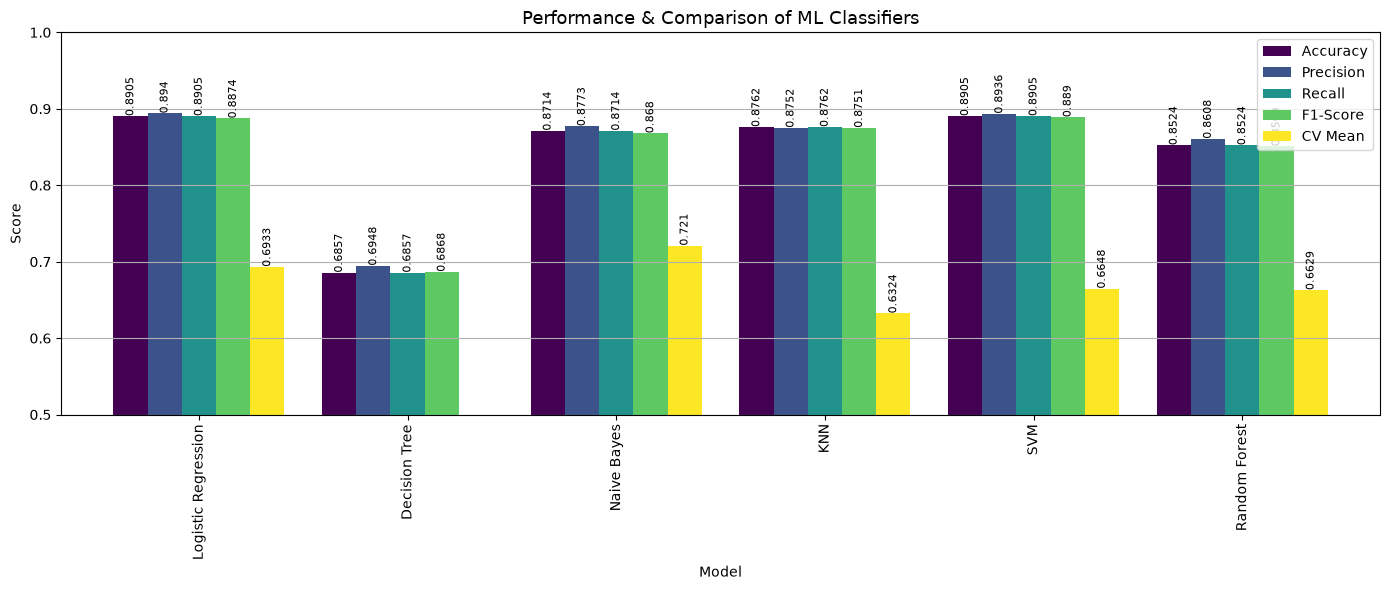

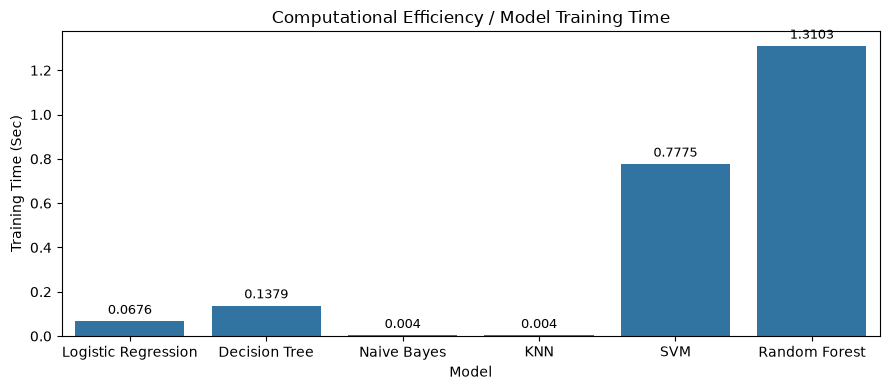

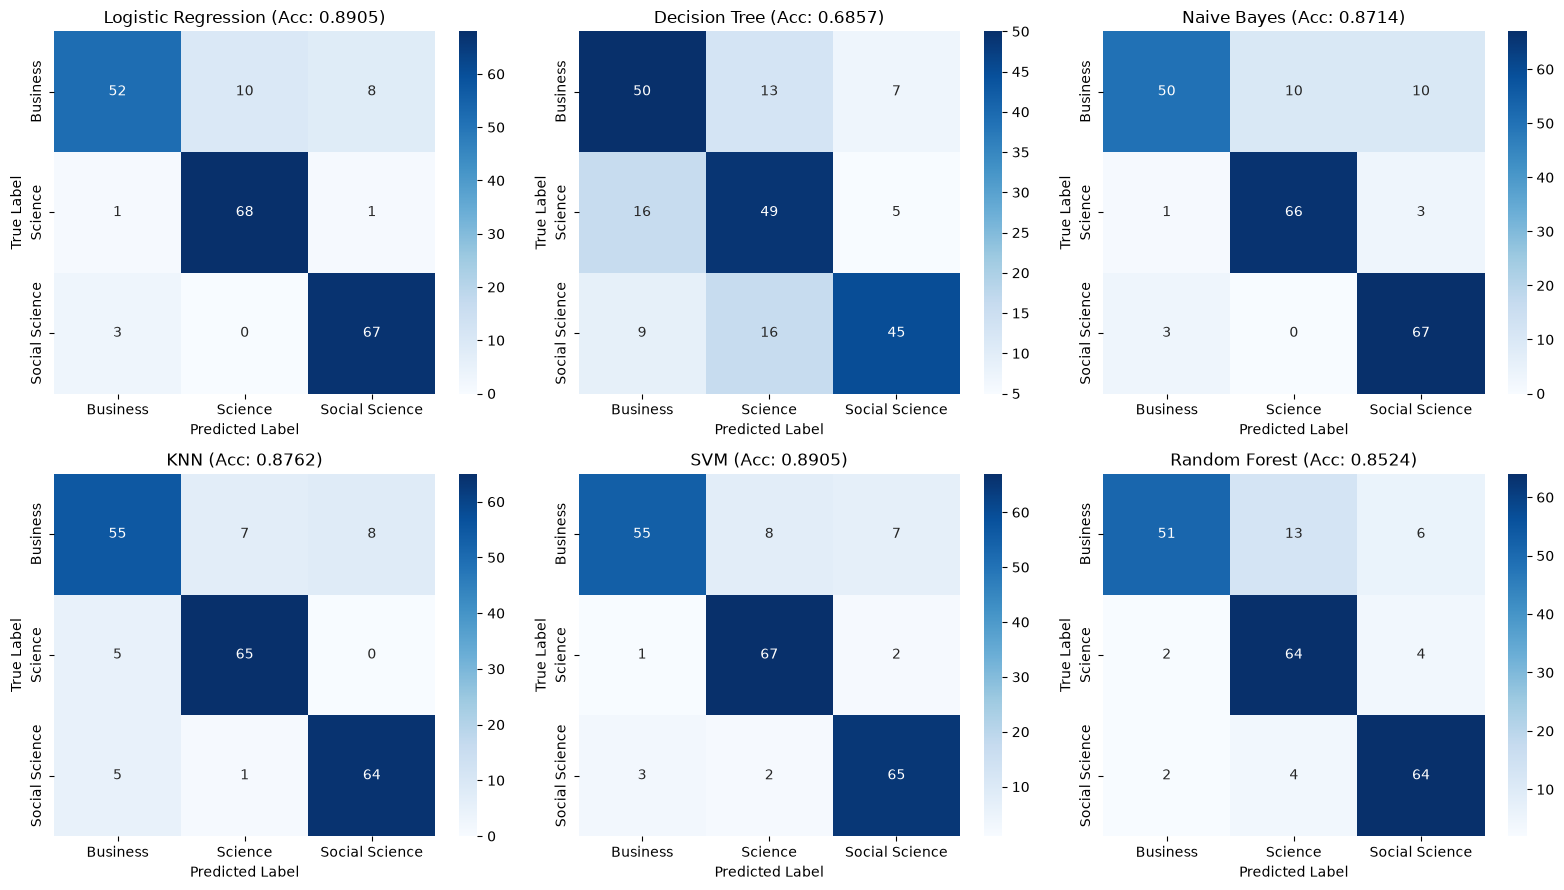

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Bar Graph.
ax = results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1-Score", "CV Mean"]].plot(kind="bar", figsize=(14, 6), colormap="viridis", width=0.82)

for c in ax.containers:
    ax.bar_label(c, fontsize=8, rotation=90)

plt.title("Performance & Comparison of ML Classifiers", fontsize=13)
plt.ylabel("Score")
plt.ylim(0.5, 1)
plt.xticks(fontsize=10)
plt.legend()
plt.grid(axis='y')
plt.tight_layout()
plt.show()

# Training Speed Comparison
plt.figure(figsize=(9, 4))
ax_time = sns.barplot(data=results_df, x="Model", y="Train Time (s)")
for c in ax_time.containers:
    ax_time.bar_label(c, fontsize=9, padding=3)
plt.title("Computational Efficiency / Model Training Time")
plt.ylabel("Training Time (Sec)")
plt.xticks()
plt.tight_layout()
plt.show()

# Confusion Matrices.
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
class_names = ["Business", "Science", "Social Science"]

for i, name in enumerate(models):
    model = models[name]
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred, labels=class_names)
    
    sns.heatmap(cm, annot=True, cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=axes[i])
    axes[i].set_title(f"{name} (Acc: {results_df.loc[i, 'Accuracy']})")
    axes[i].set_xlabel("Predicted Label")
    axes[i].set_ylabel("True Label")

plt.tight_layout()
plt.show()

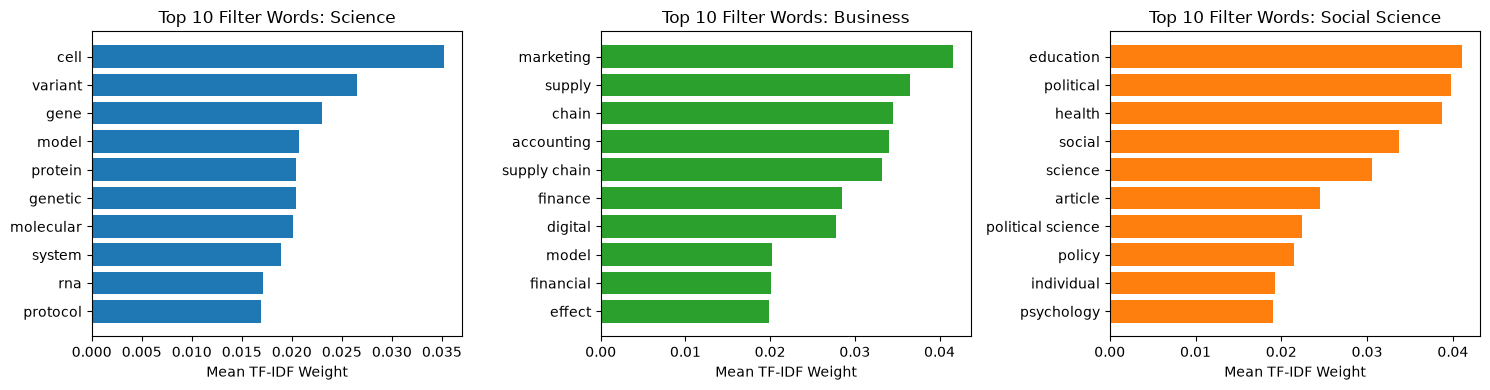

In [6]:
import numpy as np

feature_names = np.array(tfidf.get_feature_names_out())

plt.figure(figsize=(15, 4))
categories = ["Science", "Business", "Social Science"]
colors = ["#1f77b4", "#2ca02c", "#ff7f0e"]

for i, category in enumerate(categories):

    row_indices = (df['label'] == category).values
    
    # TF-IDF score for each 2,500 words in this category
    avg_tfidf = X[row_indices].mean(axis=0).A1
    
    # top 10 words with highest score
    top_indices = avg_tfidf.argsort()[-10:]
    top_words = feature_names[top_indices]
    top_scores = avg_tfidf[top_indices]
    
    # bar chart.
    plt.subplot(1, 3, i + 1)
    bars = plt.barh(top_words, top_scores, color=colors[i])
    plt.title(f"Top 10 Filter Words: {category}")
    plt.xlabel("Mean TF-IDF Weight")

plt.tight_layout()
plt.show()

This Cell Shows which filter words contribute most towards alignment of the modal to a perticular Class.

In [9]:
import joblib

best_model = models["Logistic Regression"]
joblib.dump(best_model, "best_model.pkl")
joblib.dump(tfidf, "tfidf_vectorizer.pkl")
joblib.dump(stop_words, "stop_words.pkl")
print("Model and vectorizer saved successfully!")

Model and vectorizer saved successfully!
